# Data Loading

In [1]:
import pandas as pd

data = pd.read_csv("predictions_scaffold.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
776,0,Salmonella enterica subsp. enterica serovar Ty...,CCCCCCCCCCN1c2nccc[n+]2C[C@@]1(O)c1ccc(OC)cc1,4.730487,4.816392
3576,0,Staphylococcus aureus,CN1CCN(C(=O)c2nc(-c3ccccc3)c3c(C(F)(F)F)cc(-c4...,4.946571,4.787665
3407,0,Salmonella enterica subsp. enterica serovar Ty...,Clc1ccc(-c2c[nH]c(=NCCCCCCCN=c3[nH]cc(-c4ccc(C...,4.638272,4.911518
4298,0,Staphylococcus aureus,COc1ccc(OC)c(-c2cn3nc(-c4c[nH]c5ccccc45)sc3n2)c1,5.920819,4.699320
2933,0,Staphylococcus aureus,CCCCCc1ccc(C(=O)NCCn2cc(CCCCCc3c[nH]c(=NCc4ccc...,4.795880,5.247531


# Prediction Analysis

## Metrics

In [2]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.422467,0.366348,0.246496,0.496484
Split 1,0.275339,0.424897,0.337289,0.580766
Split 2,0.453746,0.344182,0.235582,0.485368
Split 3,-0.118300,0.419851,0.351099,0.592536
Split 4,0.252131,0.434527,0.383256,0.619077
Split 5,0.116844,0.524680,0.542636,0.736638
Split 6,0.170676,0.476328,0.421760,0.649431
Split 7,0.226141,0.404410,0.320562,0.566182
Split 8,0.248700,0.419749,0.339700,0.582838
Split 9,0.384742,0.374224,0.268768,0.518428


# Graph

Text(0, 0.5, 'predicted pIC50')

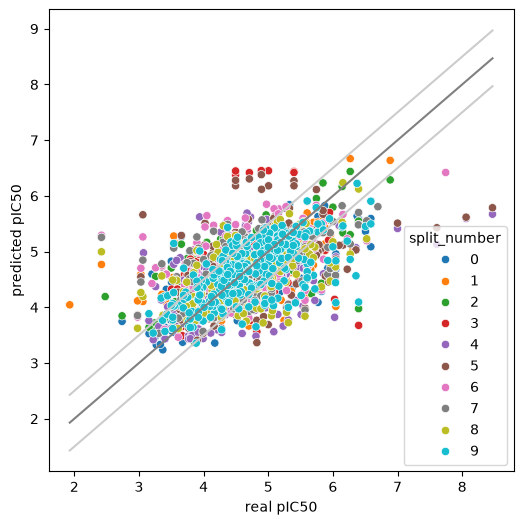

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

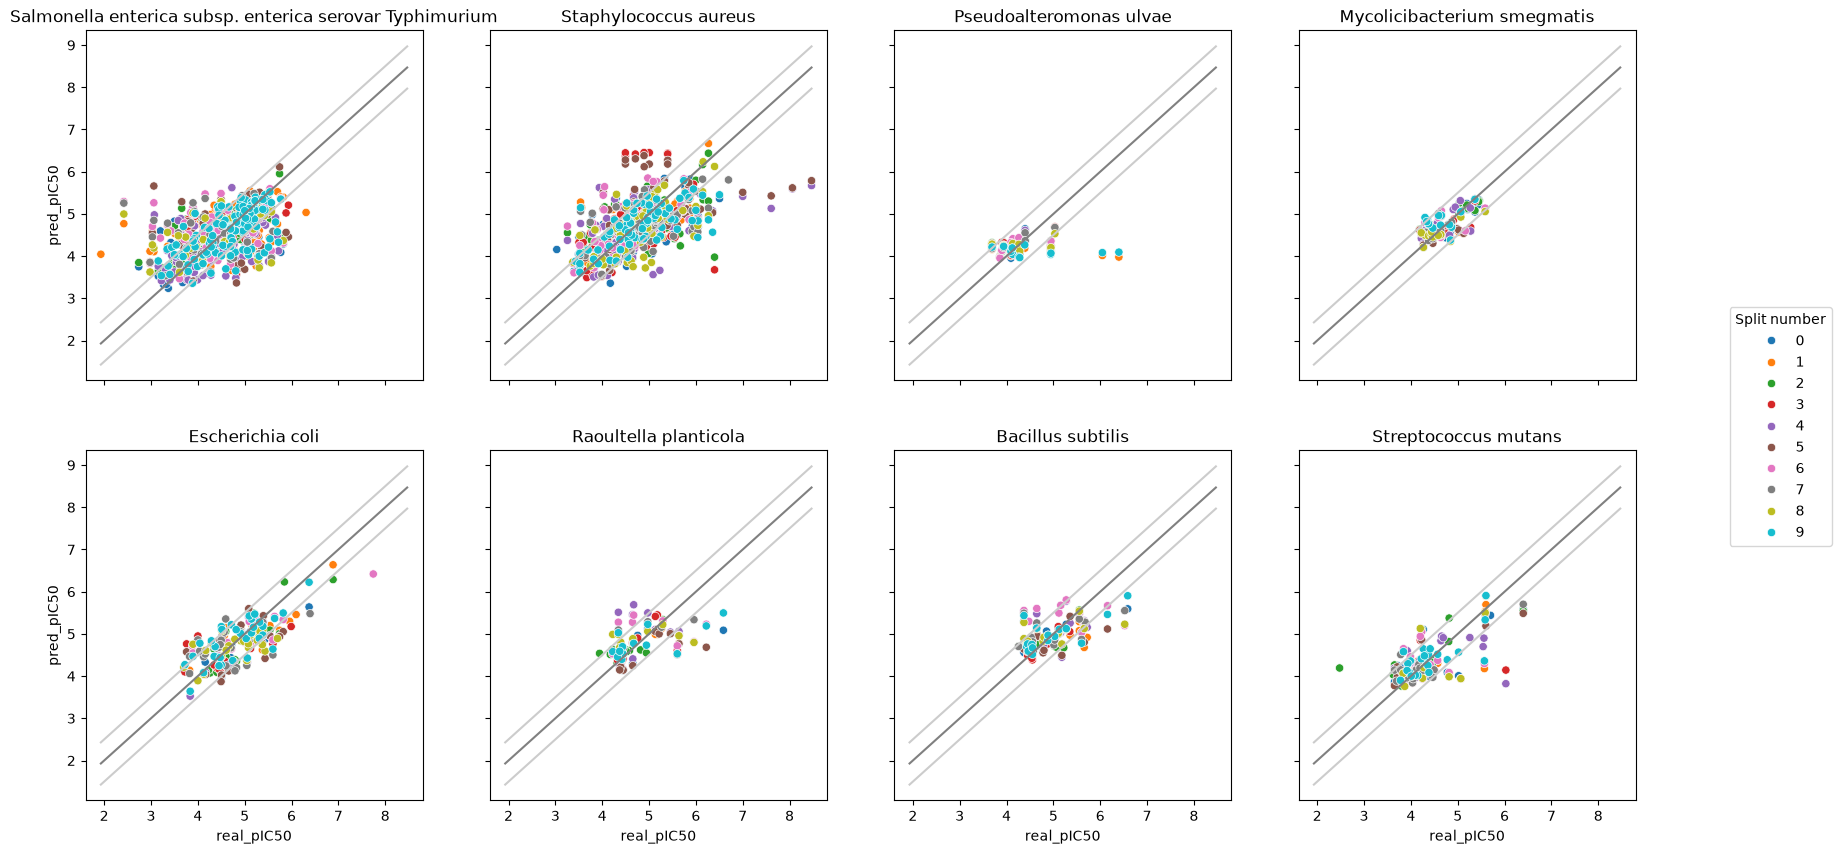

In [4]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [8]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.value_counts().index:
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Salmonella enterica subsp. enterica serovar Typhimurium,0.075,0.280,0.479,0.085,0.657,0.128
Staphylococcus aureus,0.184,0.300,0.462,0.076,0.625,0.122
Escherichia coli,0.453,0.221,0.349,0.047,0.430,0.057
Streptococcus mutans,0.300,0.398,0.331,0.051,0.485,0.089
Mycolicibacterium smegmatis,0.326,0.355,0.218,0.062,0.268,0.061
Bacillus subtilis,0.260,0.242,0.348,0.110,0.451,0.127
Pseudoalteromonas ulvae,-0.085,0.265,0.381,0.150,0.516,0.260
Raoultella planticola,0.098,0.398,0.382,0.140,0.504,0.148


In [6]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.12523506114245797
MAE 0.4659429137589052
MSE 0.41874297348289474
RMSE 0.647103526093696
..............
Staphylococcus aureus
r2_score 0.22887831745427356
MAE 0.4556966566362551
MSE 0.39674965368938914
RMSE 0.6298806662292383
..............
Pseudoalteromonas ulvae
r2_score -0.15170525664868229
MAE 0.3822172780406512
MSE 0.33088064646823045
RMSE 0.5752222583212775
..............
Mycolicibacterium smegmatis
r2_score 0.47242061699957416
MAE 0.20867109236895962
MSE 0.06973757942392257
RMSE 0.26407873716738833
..............
Escherichia coli
r2_score 0.5119242534878037
MAE 0.34575764989981317
MSE 0.1840479445221609
RMSE 0.42900809377232135
..............
Raoultella planticola
r2_score 0.18485941859090538
MAE 0.38279150021214364
MSE 0.27426879186627484
RMSE 0.5237067804280128
..............
Bacillus subtilis
r2_score 0.264167934007687
MAE 0.34962837100888844
MSE 0.21853439659349977
RMSE 0.46747662678844143
..............
Strep